In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

<h1>Import Clean Data</h1>

In [16]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            name,
            dtype=dict(
                VendorID=int,
                tpep_pickup_datetime="category",
                tpep_dropoff_datetime="category",
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                store_and_fwd_flag=str,
                PULocationID=int,
                DOLocationID=int,
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
            ),
        )
        for name in sorted(glob.glob(f"../dataset-clean/{pat}"))
    ])

In [18]:
rides_clean = load_clean("rides_sample.csv")

In [19]:
rides_clean.shape

(1800000, 23)

In [15]:
rides_clean.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'VendorID', 'tpep_pickup_datetime',
       'tpep_dropoff_datetime', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount',
       'congestion_surcharge', 'Airport_fee', 'duration_hours',
       'avg_speed_mph'],
      dtype='object')

<h1>Creating the Aggregated Dataset</h1>

In [7]:
def safe_mode(x):
    """Return the first mode, or NaN if none exists."""
    m = x.mode(dropna=True)
    return m.iloc[0] if not m.empty else np.nan

def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    df.columns = [(f"{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.groupby("PULocationID")[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
            suffixes=("", f"-{agg}-{window}-{offset}"),
        )

    return df


In [8]:
def add_zone_lags(df_zone_hour, target_cols, lags=(1, 24, 24*6), rolling_windows=(24, 24*7)):
    """
    Add lag and rolling features within each zone.

    Parameters
    ----------
    df_zone_hour : pd.DataFrame
        Must contain PULocationID and pickup_hour_dt.
    target_cols : list-like
        Columns to lag, e.g. ['zh_trip_count', 'zh_total_revenue'].
    lags : tuple
        Lag lengths in hours.
    rolling_windows : tuple
        Rolling window lengths in hours, based on shifted values to avoid leakage.

    Returns
    -------
    pd.DataFrame
    """
    df = df_zone_hour.sort_values(["PULocationID", "pickup_hour_dt"]).copy()

    for col in target_cols:
        for lag in lags:
            df[f"{col}_lag_{lag + 24}"] = df.groupby("PULocationID")[col].shift(lag)

        for w in rolling_windows:
            df[f"{col}_rollmean_{w}"] = (
                df.groupby("PULocationID")[col]
                  .shift(1)
                  .rolling(w)
                  .mean()
                  .reset_index(level=0, drop=True)
            )

            df[f"{col}_rollstd_{w}"] = (
                df.groupby("PULocationID")[col]
                  .shift(1)
                  .rolling(w)
                  .std()
                  .reset_index(level=0, drop=True)
            )

    return df

In [9]:
# deploy


df_zone_hour = build_zone_hour_panel(
    rides_clean,
    all_zones=manhat_zones,
)

df_model = add_zone_lags(
    df_zone_hour,
    target_cols=["zh_trip_count", "zh_total_revenue", "zh_total_revenue_per_time"],
    lags=(24, 24*6),
    rolling_windows=(24,)
)

df_zone_hour.tail()

,PULocationID,pickup_hour_dt,zh_trip_count,zh_total_revenue,zh_total_duration,zh_RatecodeID,zh_avg_fare,zh_avg_distance,zh_avg_speed,zh_avg_duration,zh_avg_tip,zh_avg_improv_surcharge,zh_avg_mta_tax,zh_total_revenue_per_time,hour,day_of_week,is_weekend,month,date
13307749,263,2024-12-31 19:00:00,12,200.03,2.068611,1.0,8.765833,2.002500,10.342293,0.172384,1.820000,1.0,0.5,96.697731,19,1,0,12,2024-12-31
13307750,263,2024-12-31 20:00:00,10,267.39,3.069444,1.0,18.520000,3.069000,10.169411,0.306944,3.519000,1.0,0.5,87.113484,20,1,0,12,2024-12-31
13307751,263,2024-12-31 21:00:00,17,274.64,2.104444,1.0,9.115294,1.465882,10.827068,0.123791,1.863529,1.0,0.5,130.504752,21,1,0,12,2024-12-31
13307752,263,2024-12-31 22:00:00,5,111.01,0.884722,1.0,14.480000,2.672000,11.183673,0.176944,2.722000,1.0,0.5,125.474411,22,1,0,12,2024-12-31
13307753,263,2024-12-31 23:00:00,4,65.36,0.449722,1.0,9.125000,1.322500,12.013580,0.112431,2.215000,1.0,0.5,145.334157,23,1,0,12,2024-12-31


In [10]:
df_model.columns

Index(['PULocationID', 'pickup_hour_dt', 'zh_trip_count', 'zh_total_revenue',
       'zh_total_duration', 'zh_RatecodeID', 'zh_avg_fare', 'zh_avg_distance',
       'zh_avg_speed', 'zh_avg_duration', 'zh_avg_tip',
       'zh_avg_improv_surcharge', 'zh_avg_mta_tax',
       'zh_total_revenue_per_time', 'hour', 'day_of_week', 'is_weekend',
       'month', 'date', 'zh_trip_count_lag_48', 'zh_trip_count_lag_168',
       'zh_trip_count_rollmean_24', 'zh_trip_count_rollstd_24',
       'zh_total_revenue_lag_48', 'zh_total_revenue_lag_168',
       'zh_total_revenue_rollmean_24', 'zh_total_revenue_rollstd_24',
       'zh_total_revenue_per_time_lag_48', 'zh_total_revenue_per_time_lag_168',
       'zh_total_revenue_per_time_rollmean_24',
       'zh_total_revenue_per_time_rollstd_24'],
      dtype='object')

In [11]:
df_model.shape

(13307754, 31)

<h1>Shifting Target Variables</h1>

In [12]:
# Make sure rows are in the right order
df_model = df_model.sort_values(["PULocationID", "pickup_hour_dt"]).copy()

# Target columns you want to predict 24h ahead
target_cols = [
    "zh_trip_count",
    "zh_total_revenue",
    "zh_total_revenue_per_time",
]

# Create 24h-ahead targets
for col in target_cols:
    df_model[f"{col}_target_24h"] = (
        df_model.groupby("PULocationID")[col].shift(-24)
    )

# Drop rows where the future target does not exist
df_model = df_model.dropna(
    subset=[f"{col}_target_24h" for col in target_cols]
).reset_index(drop=True)

<h1>Renaming the 24h lag variables</h1>

In [13]:
cols_to_rename = [
    "zh_trip_count",
    "zh_total_revenue",
    "zh_total_revenue_per_time",
    
    'zh_avg_fare',
    'zh_avg_distance',
    'zh_avg_speed',
    'zh_avg_duration',
    'zh_avg_tip',
    'zh_avg_improv_surcharge',
    'zh_avg_mta_tax',
    'zh_total_revenue_per_time'
]

rename_dict = {
    col: f"{col}_lag_24"
    for col in cols_to_rename
}

df_model = df_model.rename(columns=rename_dict)

In [14]:
df_model.columns

Index(['PULocationID', 'pickup_hour_dt', 'zh_trip_count_lag_24',
       'zh_total_revenue_lag_24', 'zh_total_duration', 'zh_RatecodeID',
       'zh_avg_fare_lag_24', 'zh_avg_distance_lag_24', 'zh_avg_speed_lag_24',
       'zh_avg_duration_lag_24', 'zh_avg_tip_lag_24',
       'zh_avg_improv_surcharge_lag_24', 'zh_avg_mta_tax_lag_24',
       'zh_total_revenue_per_time_lag_24', 'hour', 'day_of_week', 'is_weekend',
       'month', 'date', 'zh_trip_count_lag_48', 'zh_trip_count_lag_168',
       'zh_trip_count_rollmean_24', 'zh_trip_count_rollstd_24',
       'zh_total_revenue_lag_48', 'zh_total_revenue_lag_168',
       'zh_total_revenue_rollmean_24', 'zh_total_revenue_rollstd_24',
       'zh_total_revenue_per_time_lag_48', 'zh_total_revenue_per_time_lag_168',
       'zh_total_revenue_per_time_rollmean_24',
       'zh_total_revenue_per_time_rollstd_24', 'zh_trip_count_target_24h',
       'zh_total_revenue_target_24h', 'zh_total_revenue_per_time_target_24h'],
      dtype='object')

<h1>Investigate Categorical Features Against Target Variables</h1>

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_categorical_vs_targets(df, cat_col, targets=None, agg="mean", sort_index=True):
    """
    Plot categorical feature vs multiple target variables.

    Parameters
    ----------
    df : pd.DataFrame
    cat_col : str
        Categorical column name (e.g. 'hour', 'day_of_week', 'PULocationID')
    targets : list
        Target columns to plot
    agg : str
        Aggregation method ('mean', 'median', etc.)
    sort_index : bool
        Whether to sort categories (useful for ordered categories like hour)
    """

    if targets is None:
        targets = [
            "zh_trip_count_target_24h",
            "zh_total_revenue_target_24h",
            "zh_total_revenue_per_time_target_24h"
        ]

    fig, axes = plt.subplots(1, len(targets), figsize=(5 * len(targets), 4))

    if len(targets) == 1:
        axes = [axes]

    for i, target in enumerate(targets):
        grouped = df.groupby(cat_col)[target].agg(agg)

        if sort_index:
            grouped = grouped.sort_index()

        axes[i].bar(grouped.index.astype(str), grouped.values)
        axes[i].set_title(f"{target} vs {cat_col}")
        axes[i].set_xlabel(cat_col)
        axes[i].set_ylabel(f"{agg} {target}")

        # Rotate labels if many categories
        if grouped.shape[0] > 10:
            axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

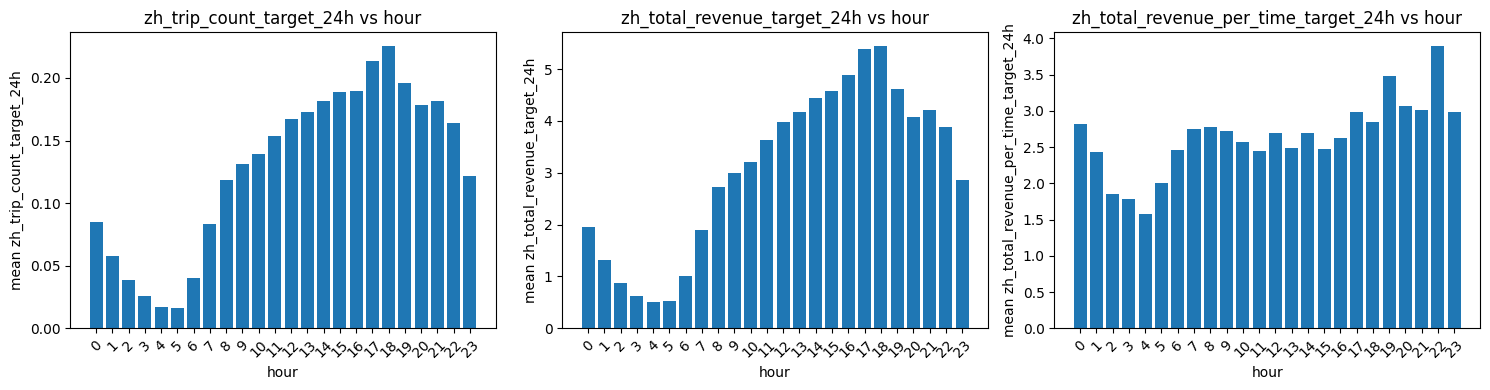

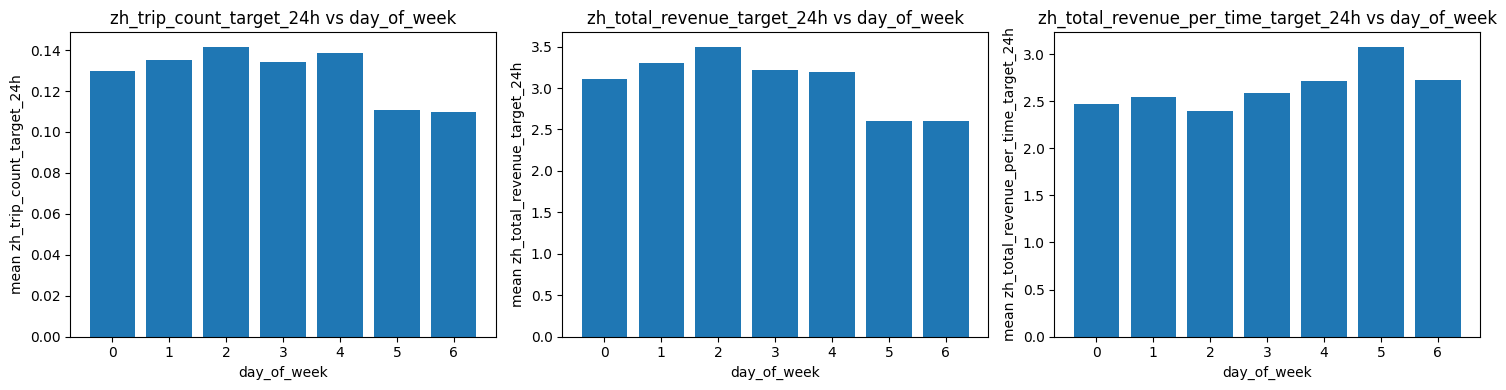

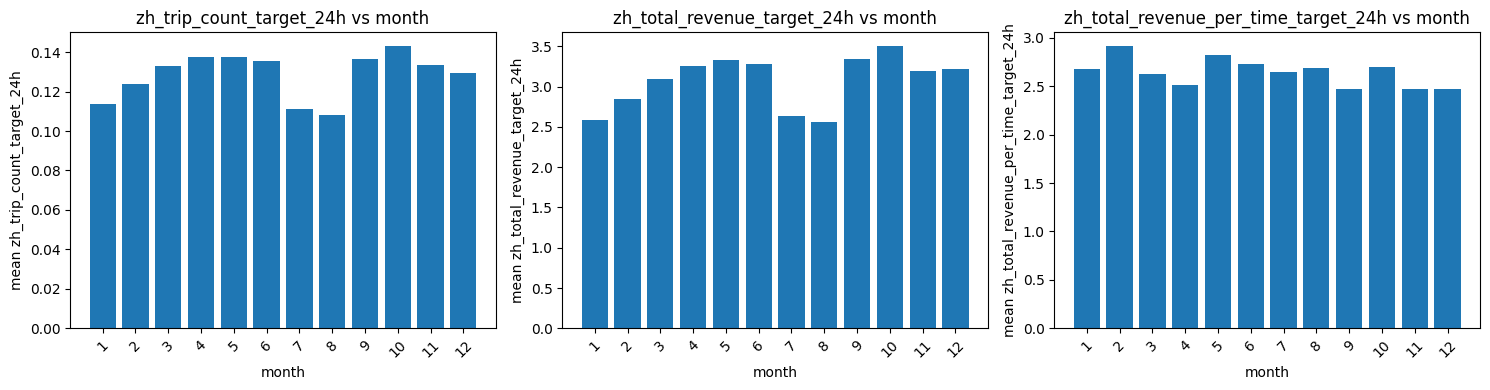

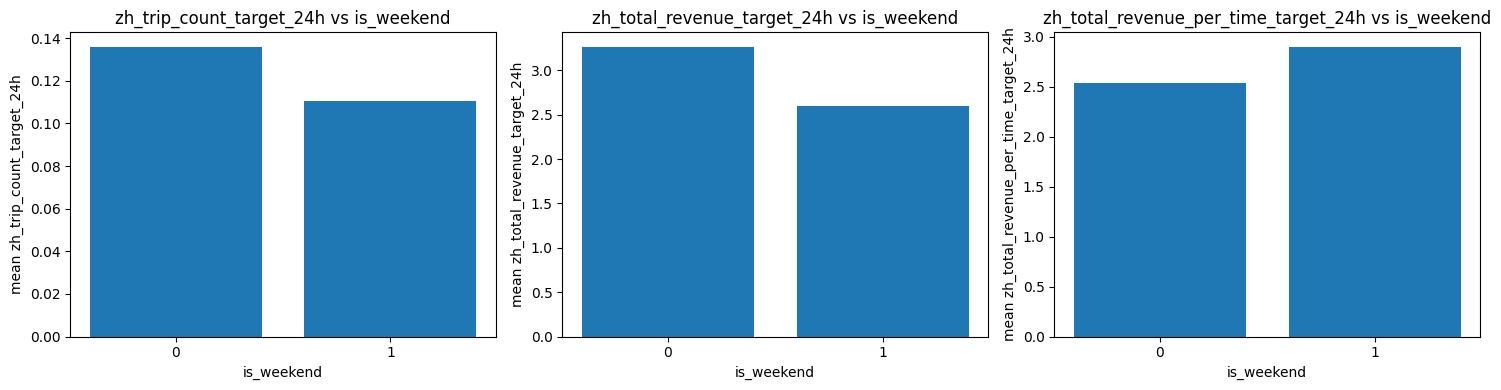

In [16]:
plot_categorical_vs_targets(df_model, "hour")
plot_categorical_vs_targets(df_model, "day_of_week")
plot_categorical_vs_targets(df_model, "month")
plot_categorical_vs_targets(df_model, "is_weekend")

<h1>Investigate avg_trip_count vs Lags</h1>

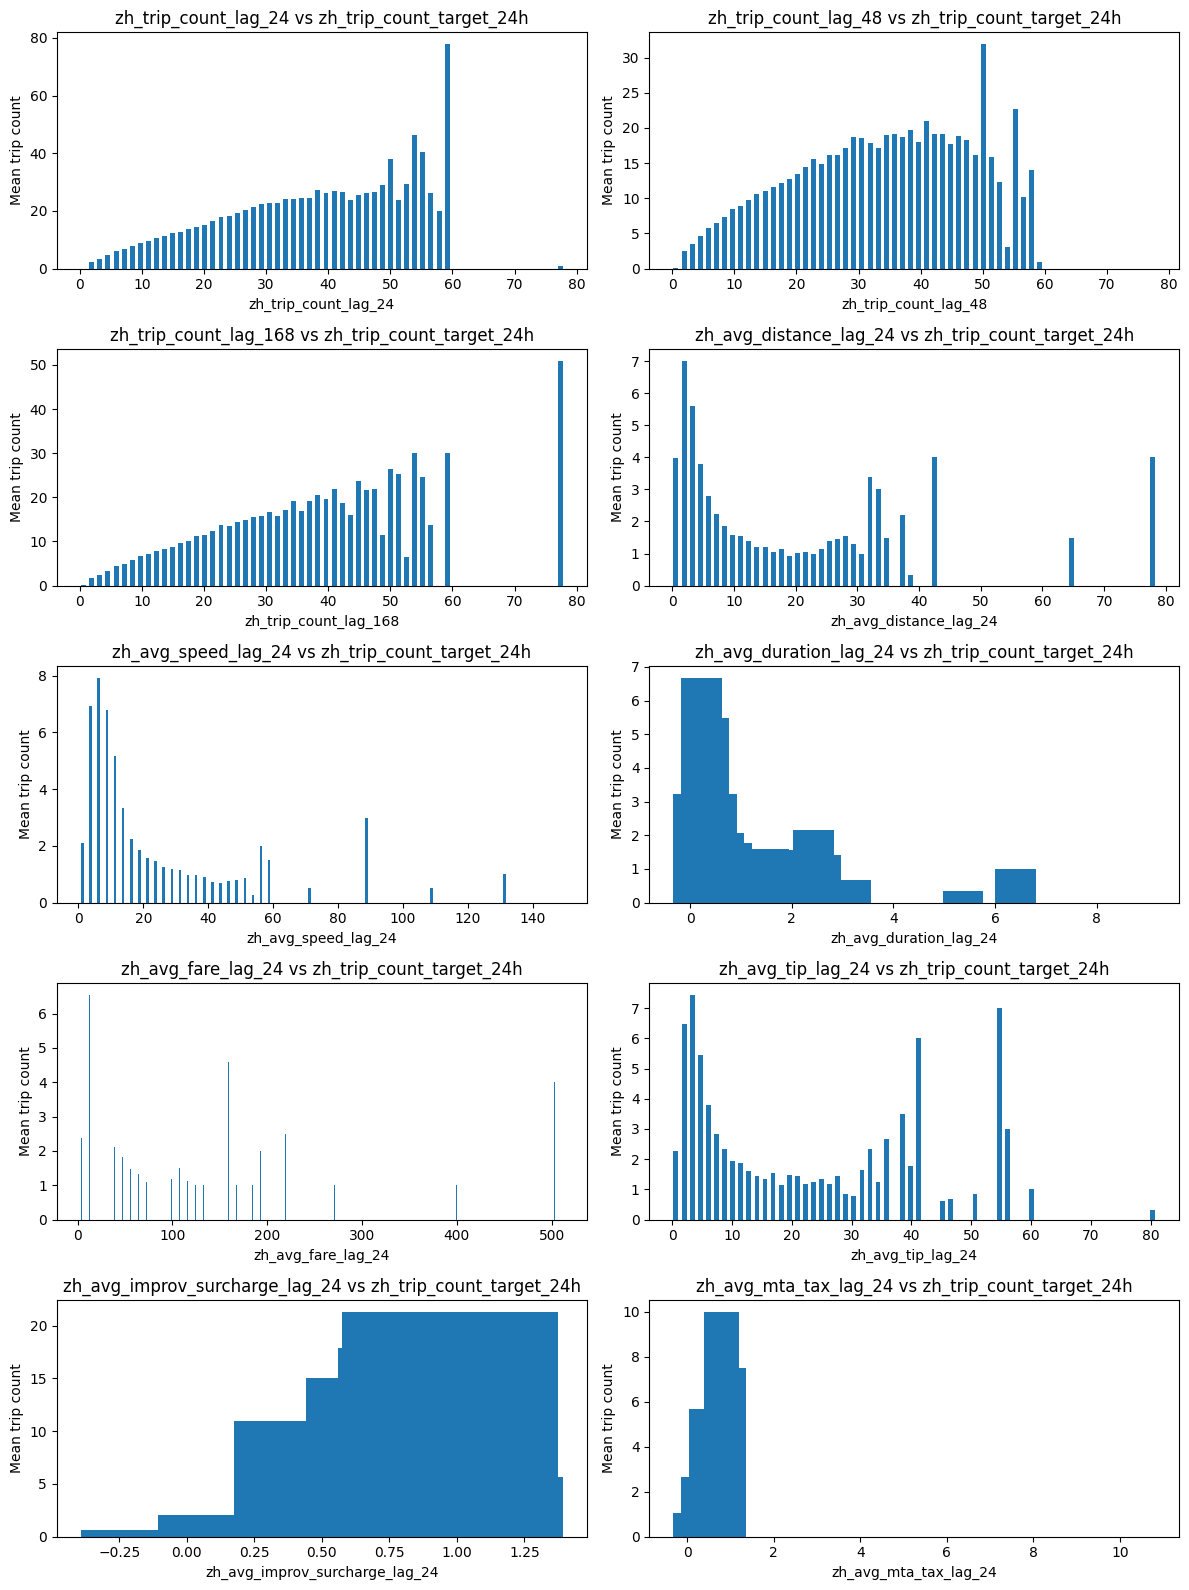

In [17]:
fig, axes = plt.subplots(6,2, figsize=(12, 16))
axes = axes.flatten()

components = [
    'zh_trip_count_lag_24',
    'zh_trip_count_lag_48',
    'zh_trip_count_lag_168',
    
    'zh_avg_distance_lag_24',
    'zh_avg_speed_lag_24',
    'zh_avg_duration_lag_24',
    
    'zh_avg_fare_lag_24',
    'zh_avg_tip_lag_24',
    'zh_avg_improv_surcharge_lag_24',
    'zh_avg_mta_tax_lag_24',
]

target = 'zh_trip_count_target_24h'

for i, col in enumerate(components):
    ax = axes[i]
    
    # Create equal-sized bins
    df_temp = df_model[[col, target]].dropna().copy()
    df_temp['bin'] = pd.cut(df_temp[col], bins=60, duplicates='drop')
    
    grouped = df_temp.groupby('bin', observed=False)[target].mean()
    
    # use bin centres
    bin_centres = [interval.mid for interval in grouped.index]
    
    ax.bar(bin_centres, grouped.values)
    ax.set_title(f"{col} vs {target}")
    ax.set_xlabel(col)
    ax.set_ylabel("Mean trip count")

plt.tight_layout()
plt.show()

In [18]:
df_model.loc[
    df_model['zh_total_revenue_per_time_lag_24'].idxmax(),
    ['PULocationID', 'pickup_hour_dt', 'zh_total_revenue_per_time_lag_24', 'zh_trip_count_lag_24','zh_total_revenue_lag_24']
]



PULocationID                                         75
pickup_hour_dt                      2024-05-13 22:00:00
zh_total_revenue_per_time_lag_24               362880.0
zh_trip_count_lag_24                                  1
zh_total_revenue_lag_24                           100.8
Name: 2501400, dtype: object

In [19]:
(df_model['zh_total_revenue_per_time_lag_24'] > 10000).sum()

np.int64(89)

In [20]:
zone = 75
hour_start = pd.Timestamp("2024-05-13 22:00:00")
hour_end = hour_start + pd.Timedelta(hours=1)

# Ensure datetime is parsed
rides_clean["tpep_pickup_datetime"] = pd.to_datetime(rides_clean["tpep_pickup_datetime"])

rows = rides_clean[
    (rides_clean["PULocationID"] == zone) &
    (rides_clean["tpep_pickup_datetime"] >= hour_start) &
    (rides_clean["tpep_pickup_datetime"] < hour_end)
]

rows

,Unnamed: 0.1,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
324641,379386,1441541,2,2024-05-13 22:59:02,2024-05-13 22:59:03,2.0,0.02,5.0,False,75,...,0.0,0.0,16.8,0.0,1.0,100.8,0.0,0.0,0.000278,72.0


<h1>Investigate avg_trip_count vs rolling</h1>

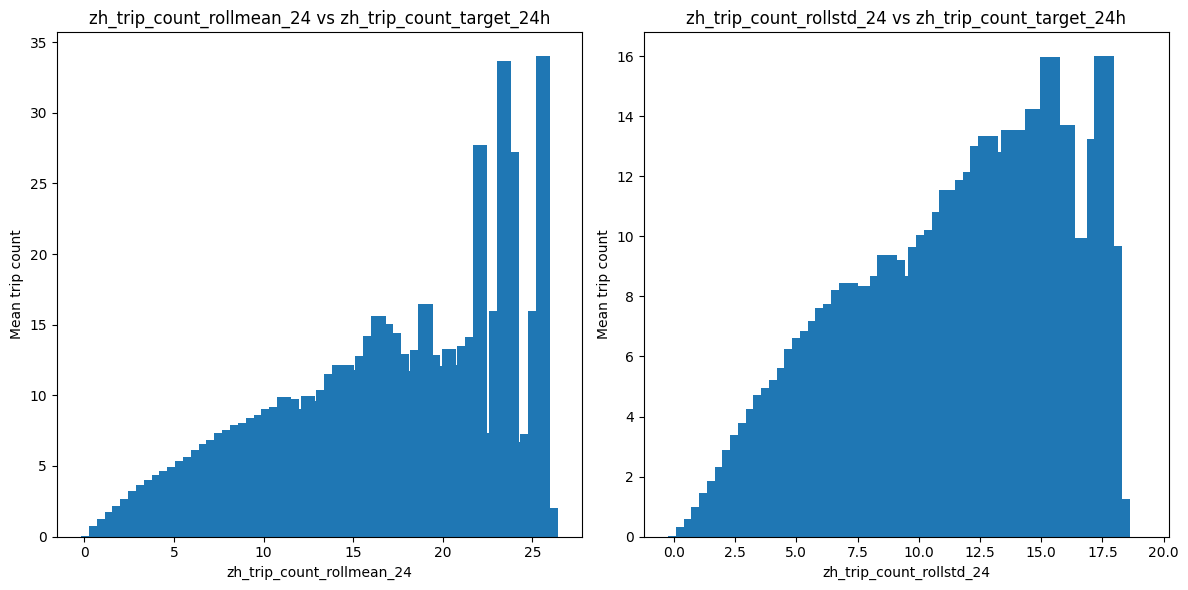

In [21]:
fig, axes = plt.subplots(1,2, figsize=(12, 6))
axes = axes.flatten()

components = [
    'zh_trip_count_rollmean_24',
    'zh_trip_count_rollstd_24'
]

target = 'zh_trip_count_target_24h'

for i, col in enumerate(components):
    ax = axes[i]
    
    # Create equal-sized bins
    df_temp = df_model[[col, target]].dropna().copy()
    df_temp['bin'] = pd.cut(df_temp[col], bins=60, duplicates='drop')
    
    grouped = df_temp.groupby('bin', observed=False)[target].mean()
    
    # use bin centres
    bin_centres = [interval.mid for interval in grouped.index]
    
    ax.bar(bin_centres, grouped.values)
    ax.set_title(f"{col} vs {target}")
    ax.set_xlabel(col)
    ax.set_ylabel("Mean trip count")

plt.tight_layout()
plt.show()

<h1>Investigate total_revenue vs Lags</h1>

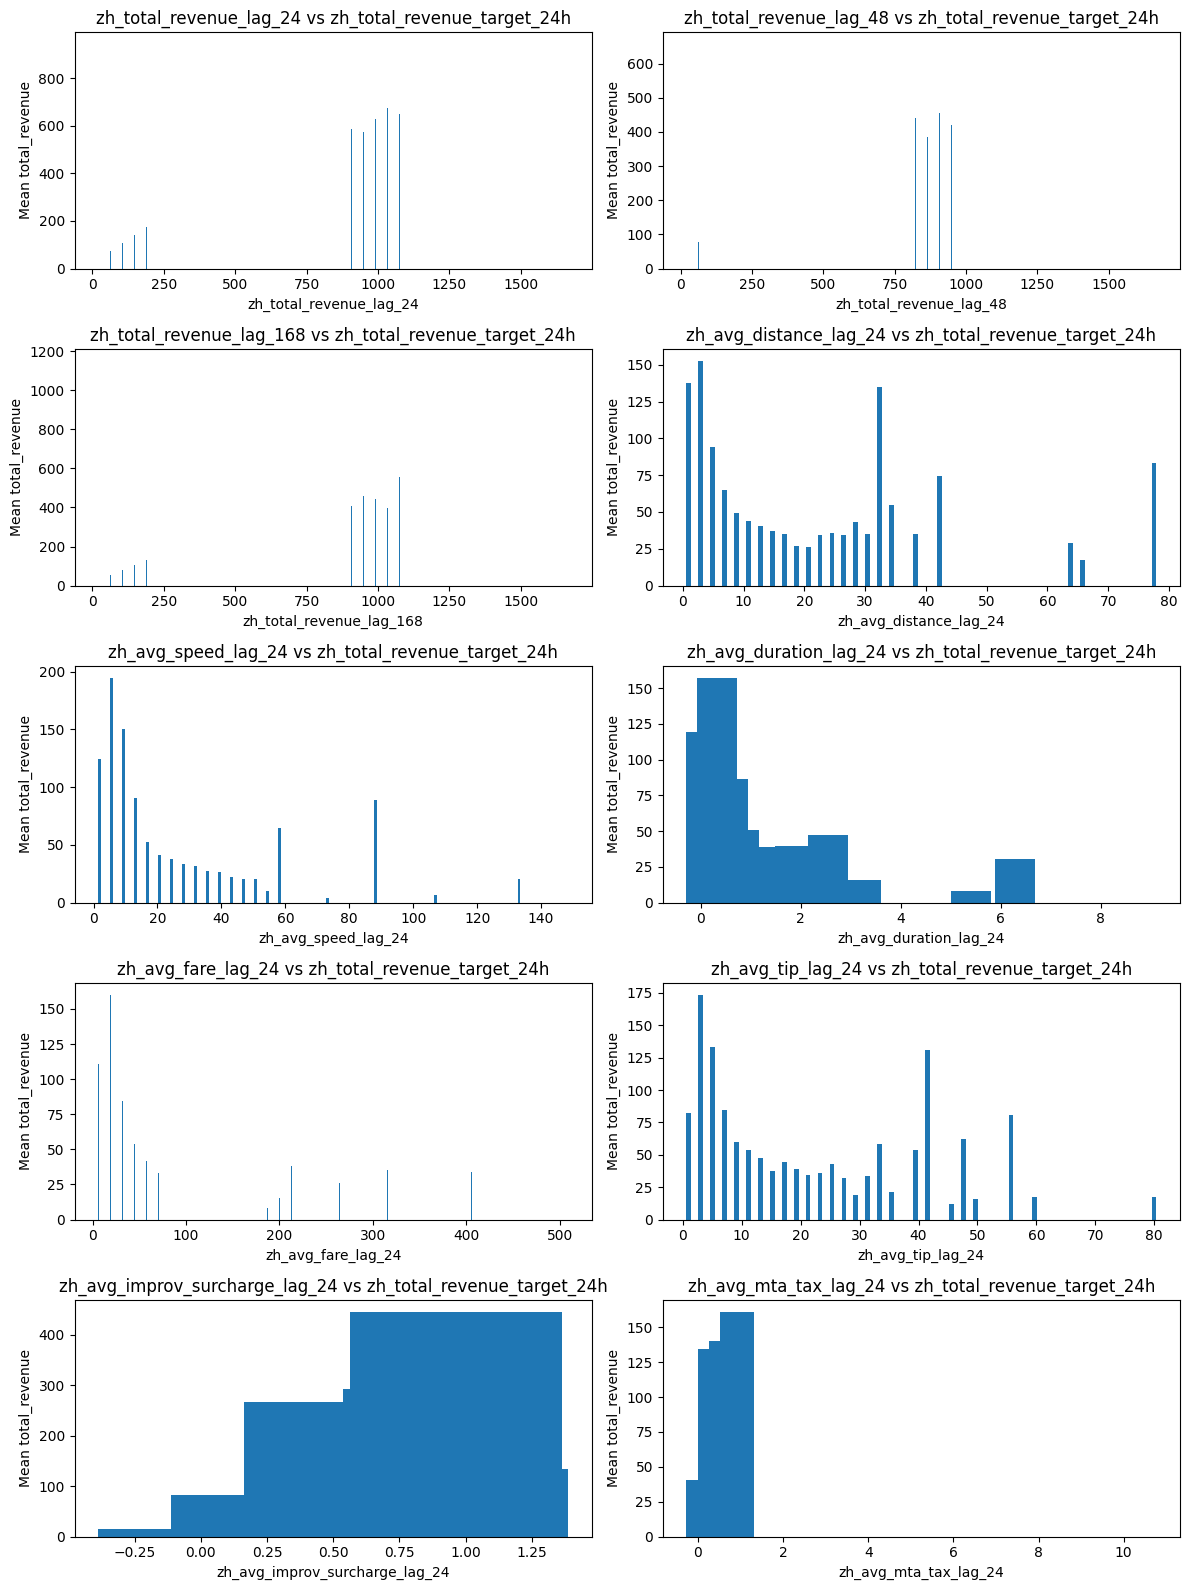

In [22]:
fig, axes = plt.subplots(5,2, figsize=(12, 16))
axes = axes.flatten()

components = [
    'zh_total_revenue_lag_24',
    'zh_total_revenue_lag_48',
    'zh_total_revenue_lag_168',
    
    'zh_avg_distance_lag_24',
    'zh_avg_speed_lag_24',
    'zh_avg_duration_lag_24',
    
    'zh_avg_fare_lag_24',
    'zh_avg_tip_lag_24',
    'zh_avg_improv_surcharge_lag_24',
    'zh_avg_mta_tax_lag_24',
]

target = 'zh_total_revenue_target_24h'

for i, col in enumerate(components):
    ax = axes[i]
    
    # Create equal-sized bins
    df_temp = df_model[[col, target]].dropna().copy()
    df_temp['bin'] = pd.cut(df_temp[col], bins=40, duplicates='drop')
    
    grouped = df_temp.groupby('bin', observed=False)[target].mean()
    
    # use bin centres
    bin_centres = [interval.mid for interval in grouped.index]
    
    ax.bar(bin_centres, grouped.values)
    ax.set_title(f"{col} vs {target}")
    ax.set_xlabel(col)
    ax.set_ylabel("Mean total_revenue")

plt.tight_layout()
plt.show()

<h1>Investigating total_revenue vs rolling features</h1>

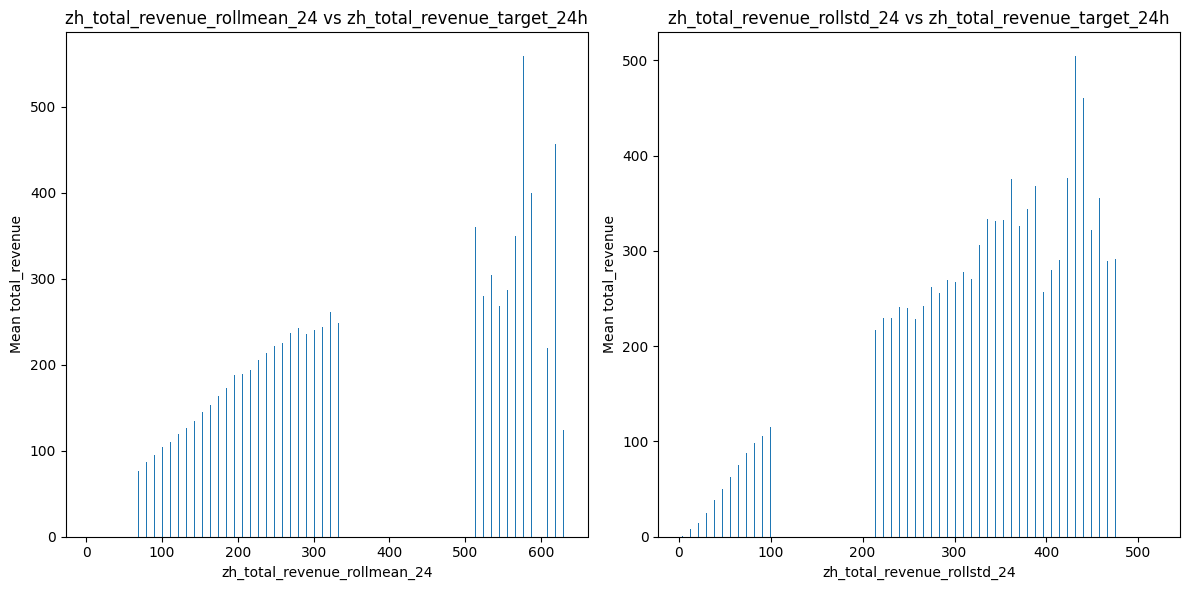

In [23]:
fig, axes = plt.subplots(1,2, figsize=(12, 6))
axes = axes.flatten()

components = [
    'zh_total_revenue_rollmean_24',
    'zh_total_revenue_rollstd_24'
]

target = 'zh_total_revenue_target_24h'

for i, col in enumerate(components):
    ax = axes[i]
    
    # Create equal-sized bins
    df_temp = df_model[[col, target]].dropna().copy()
    df_temp['bin'] = pd.cut(df_temp[col], bins=60, duplicates='drop')
    
    grouped = df_temp.groupby('bin', observed=False)[target].mean()
    
    # use bin centres
    bin_centres = [interval.mid for interval in grouped.index]
    
    ax.bar(bin_centres, grouped.values)
    ax.set_title(f"{col} vs {target}")
    ax.set_xlabel(col)
    ax.set_ylabel("Mean total_revenue")

plt.tight_layout()
plt.show()

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_full_correlation(df, cols, title):
    """
    Plot full correlation matrix for selected columns.

    Parameters
    ----------
    df : pd.DataFrame
    cols : list
        Columns to include (features + targets)
    """

    # Keep only numeric columns (safety)
    df_corr = df[cols].select_dtypes(include='number')

    # Compute correlation
    corr = df_corr.corr()

    # Plot
    plt.figure(figsize=(12, 12))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

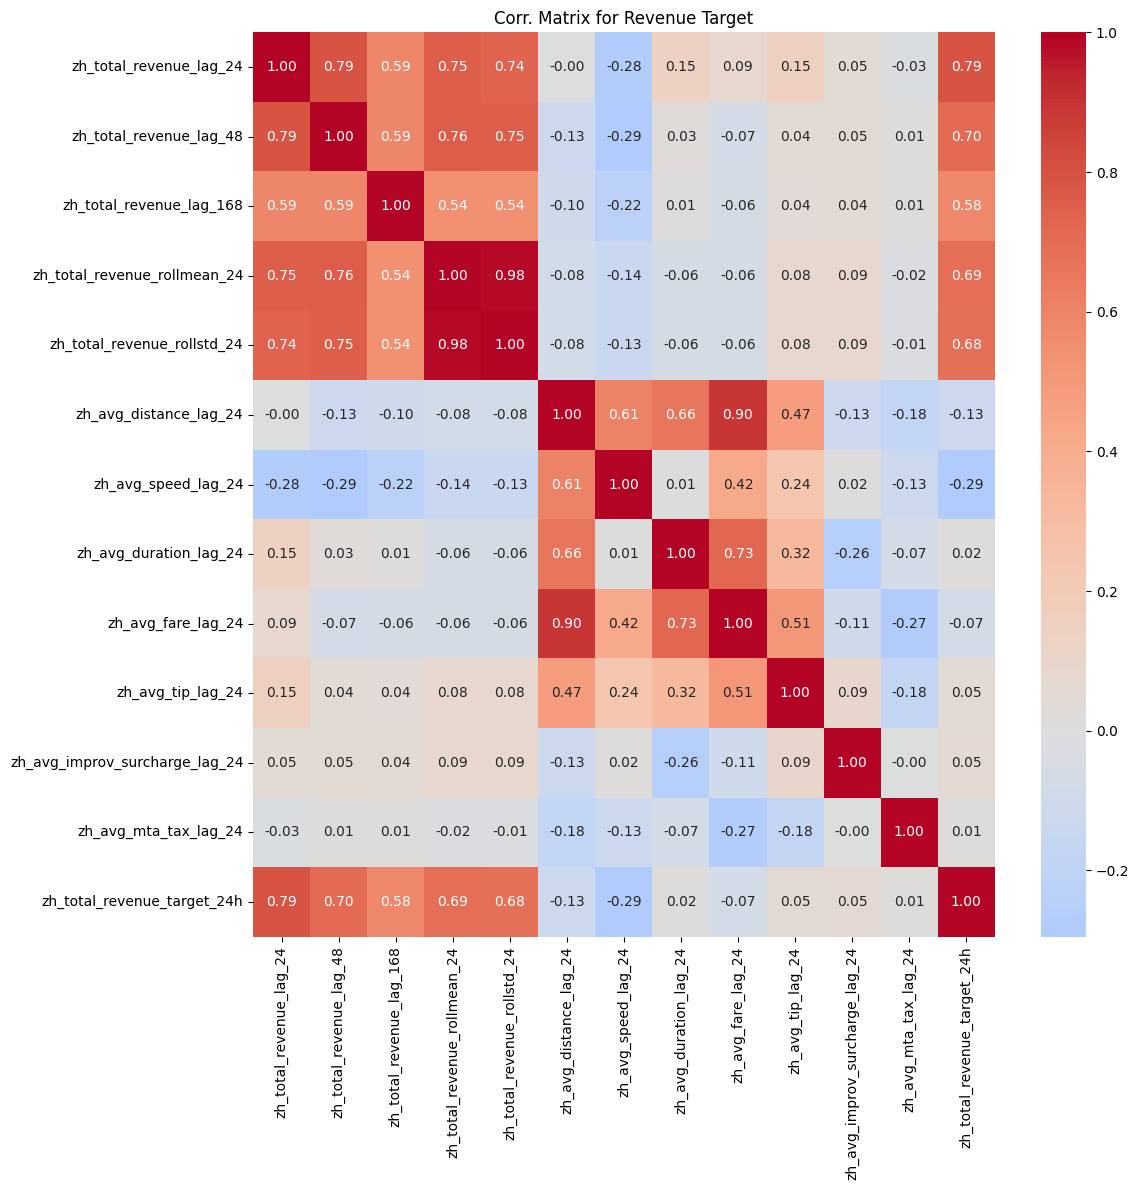

In [26]:
cols_demand = [
    'zh_trip_count_lag_24',
    'zh_trip_count_lag_48',
    'zh_trip_count_lag_168',

    'zh_trip_count_rollmean_24',
    'zh_trip_count_rollstd_24',

    'zh_avg_distance_lag_24',
    'zh_avg_speed_lag_24',
    'zh_avg_duration_lag_24',
    
    'zh_avg_fare_lag_24',
    'zh_avg_tip_lag_24',
    'zh_avg_improv_surcharge_lag_24',
    'zh_avg_mta_tax_lag_24',

    'zh_trip_count_target_24h',

]

cols_revenue = [
    'zh_total_revenue_lag_24',
    'zh_total_revenue_lag_48',
    'zh_total_revenue_lag_168',
    
    'zh_total_revenue_rollmean_24',
    'zh_total_revenue_rollstd_24',
    
    'zh_avg_distance_lag_24',
    'zh_avg_speed_lag_24',
    'zh_avg_duration_lag_24',
    
    'zh_avg_fare_lag_24',
    'zh_avg_tip_lag_24',
    'zh_avg_improv_surcharge_lag_24',
    'zh_avg_mta_tax_lag_24',

    'zh_total_revenue_target_24h',

]

# plot_full_correlation(df_model, cols_demand, 'Corr. Matrix for Demand Target')
plot_full_correlation(df_model, cols_revenue, 'Corr. Matrix for Revenue Target')


<h1>Demand Feature Summary</h1>

| Feature                          | Trip Count (t+24) | Target Corr. | Feature Corr. | Notes |
|----------------------------------|------------------|----------------|----------------|---------------|
| zh_trip_count_lag_24            |Partial linear rel.|0.82 ~ High|Other trip_count lag and roll. features|
| zh_trip_count_lag_48            |Partial linear rel.|0.73 ~ High|The same.|
| zh_trip_count_lag_168           |Quite linear.|0.6 ~ Med|The same.|
| zh_trip_count_rollmean_24       |Potentially linear.|0.7 ~ High|Heavily correlated with ...rollstd_24|
| zh_trip_count_rollstd_24        |Potentially linear.|0.69 ~ High|Heavily correlated with ...rollmean_24|
| zh_avg_distance_lag_24          |Partial exp. decay.|-0.16 ~ Low|Speed, duration, tip, very cor with avg_fare|
| zh_avg_speed_lag_24             |Partial expo. decay.|-0.29 ~ Low|avg_fare and quite corr. with avg_distance|
| zh_avg_duration_lag_24          |Partial expo. decay (rough).|-0.02 ~ V Low|Very corr. with avg_distance and avg_fare. avg_tip too.|
| zh_avg_fare_lag_24              |Appears random.|-0.1 ~ Low|avg_speed, duration, tip. Very corr. with avg_distance.|
| zh_avg_tip_lag_24               |Potential quad. poly.|0.03 ~ V Low|Corr. with avg_distance and avg_fare.|
| zh_avg_improv_surcharge_lag_24  |Increasing trend. Outliers?|0.06 ~ V Low|No significant corr.|
| zh_avg_mta_tax_lag_24           |Increasing trend. Outliers?|0.02 ~ V Low|No significant corr.|
| hour                            |Looks good. Greatest in evening.|N/A||
| day_of_week                     |Slightly lower on weekends.|N/A||
| month                           |Slightly lower in July/Aug.|N/A||
| is_weekend                      |Lower at weekend.|N/A||

<h1>Revenue Feature Summary</h1>

| Feature                          | Total Revenue (t+24) | Target Corr. | Feature Corr. | Notes |
|----------------------------------|------------------|----------------|----------------|---------------|
| zh_total_revenue_lag_24         |Increasing. Perhaps linear|0.79 ~ High|Other total_revenue lag and roll. features|
| zh_total_revenue_lag_48         |Clear relationship.|0.7 ~ High|The same|
| zh_total_revenue_lag_168        |Clear relationship.|0.58 ~ High|The same|
| zh_total_revenue_rollmean_24    |Clear relationship|0.69 ~ High|The same; highly correlated with rollstd|
| zh_total_revenue_rollstd_24     |Partially linear. Clear relationship.|0.68 ~ High|The same; highly correlated with rollmean|
| zh_avg_distance_lag_24          |Expo. decay.|-0.13 ~ Low|Speed, duration, tip, very cor with avg_fare|
| zh_avg_speed_lag_24             |Expo. decay.|-0.29 ~ Low|avg_fare and quite corr. with avg_distance|
| zh_avg_duration_lag_24          |Expo decay. Outliers?|0.02 ~ V Low|Very corr. with avg_distance and avg_fare. avg_tip too.|
| zh_avg_fare_lag_24              |Unclear relationship.|-0.07 ~ V Low|avg_speed, duration, tip. Very corr. with avg_distance.|
| zh_avg_tip_lag_24               |Expo. decay|0.05 ~ V Low|Corr. with avg_distance and avg_fare.|
| zh_avg_improv_surcharge_lag_24  |Appears to be increasing. A value below 0?|0.05 ~ V Low|No significant corr.|
| zh_avg_mta_tax_lag_24           |Appears to be increasing. Outliers?|0.1 ~ Low|No significant corr.|
| hour                            |Greatest in the evening.|N/A|
| day_of_week                     |Lower on weekends.|N/A|
| month                           |Lower in July/Aug|N/A|
| is_weekend                      |Lower at weekend.|N/A|

<h1>Investigating relationships between the target variables:</h1>

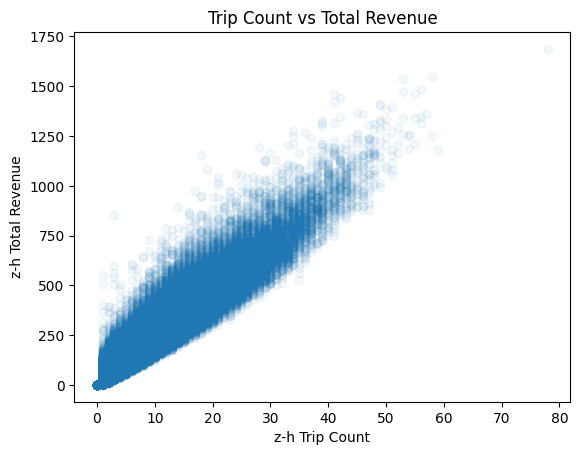

In [37]:
df_plot = df_model[
    ['zh_trip_count_target_24h', 'zh_total_revenue_target_24h']
].dropna()

plt.scatter(df_plot.iloc[:, 0], df_plot.iloc[:, 1], alpha=0.05)

plt.xlabel('z-h Trip Count')
plt.ylabel('z-h Total Revenue')
plt.title('Trip Count vs Total Revenue')

plt.show()

In [38]:
# A correlation comparison
df_model[['zh_trip_count_target_24h', 'zh_total_revenue_target_24h']].corr()

,zh_trip_count_target_24h,zh_total_revenue_target_24h
zh_trip_count_target_24h,1.000000,0.976906
zh_total_revenue_target_24h,0.976906,1.000000


<h2>Analysis - clearly the target variables are very correlated.</h2>

<h1>Fitting Some Benchmark Models</h1>

In [31]:
from sklearn.model_selection import TimeSeriesSplit

df_model_ts = df_model.sort_values('pickup_hour_dt').copy()

target = 'zh_trip_count_target_24h'

features = [
    'zh_trip_count_lag_24',
    'zh_trip_count_lag_48',
    'zh_trip_count_lag_168',
    'zh_trip_count_rollmean_24',
    'zh_trip_count_rollstd_24',
    'zh_avg_distance_lag_24',
    'zh_avg_speed_lag_24',
    'zh_avg_duration_lag_24',
    'zh_avg_fare_lag_24',
    'zh_avg_tip_lag_24',
    'zh_avg_improv_surcharge_lag_24',
    'zh_avg_mta_tax_lag_24',
    'hour',
    'day_of_week',
    'month',
    'is_weekend'
]

df_model_ts = df_model_ts[features + [target, 'pickup_hour_dt']].dropna().copy()

X = df_model_ts[features]
y = df_model_ts[target]

tscv = TimeSeriesSplit(n_splits=5)

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

train_rmse_scores = []
train_r2_scores = []

val_rmse_scores = []
val_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    # --- TRAIN predictions ---
    y_train_pred = model.predict(X_train_scaled)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    train_r2   = r2_score(y_train, y_train_pred)

    train_rmse_scores.append(train_rmse)
    train_r2_scores.append(train_r2)

    # --- VALIDATION predictions ---
    y_val_pred = model.predict(X_val_scaled)

    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_r2   = r2_score(y_val, y_val_pred)

    val_rmse_scores.append(val_rmse)
    val_r2_scores.append(val_r2)

    print(f"Fold {fold}")
    print(f"  Train RMSE = {train_rmse:.3f}, R^2 = {train_r2:.3f}")
    print(f"  Val   RMSE = {val_rmse:.3f}, R^2 = {val_r2:.3f}")

print("\nOverall performance:")
print(f"Mean RMSE = {np.mean(rmse_scores):.3f} ± {np.std(rmse_scores):.3f}")
print(f"Mean R^2  = {np.mean(r2_scores):.3f} ± {np.std(r2_scores):.3f}")

Fold 1
  Train RMSE = 4.173, R^2 = 0.521
  Val   RMSE = 4.439, R^2 = 0.540
Fold 2
  Train RMSE = 4.305, R^2 = 0.533
  Val   RMSE = 4.345, R^2 = 0.535
Fold 3
  Train RMSE = 4.317, R^2 = 0.534
  Val   RMSE = 3.723, R^2 = 0.516
Fold 4
  Train RMSE = 4.176, R^2 = 0.532
  Val   RMSE = 4.360, R^2 = 0.561
Fold 5
  Train RMSE = 4.212, R^2 = 0.539
  Val   RMSE = 4.475, R^2 = 0.535

Overall performance:
Mean RMSE = 4.122 ± 0.258
Mean R^2  = 0.568 ± 0.014


In [33]:
import numpy as np

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

tscv = TimeSeriesSplit(n_splits=5)

rmse_scores = []
r2_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=5059,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2   = r2_score(y_val, y_pred)

    rmse_scores.append(rmse)
    r2_scores.append(r2)

    print(f"Fold {fold}: RMSE = {rmse:.3f}, R^2 = {r2:.3f}")

print("\nOverall performance:")
print(f"Mean RMSE = {np.mean(rmse_scores):.3f}")
print(f"Mean R^2  = {np.mean(r2_scores):.3f}")

Fold 1: RMSE = 4.089, R^2 = 0.610
Fold 2: RMSE = 4.200, R^2 = 0.566
Fold 3: RMSE = 3.550, R^2 = 0.560
Fold 4: RMSE = 4.156, R^2 = 0.601
Fold 5: RMSE = 4.359, R^2 = 0.559

Overall performance:
Mean RMSE = 4.071
Mean R^2  = 0.579


In [35]:
import pandas as pd

importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values(by='importance', ascending=False)

print(importance)

                     feature  importance
0       zh_trip_count_lag_24    0.521883
1  zh_trip_count_rollmean_24    0.139894
2     zh_avg_distance_lag_24    0.118257
3                       hour    0.093787
4                day_of_week    0.069115
5                      month    0.057065


In [34]:
df_model['zh_trip_count_target_24h'].mean()

np.float64(0.12860689888200133)